# Mushroom Edibility Classification

### An end-to-end machine-learning project for classifying mushrooms as edible or poisonous

## About this project

This notebook builds a reproducible binary-classification pipeline from raw categorical mushroom characteristics to a versioned model artifact used by a FastAPI application. The local dataset contains **8,124 mushroom records**, **22 categorical input features**, and one target named `class`. The original labels are `e` for edible and `p` for poisonous.

The project answers four practical questions:

1. Can observable mushroom characteristics distinguish poisonous from edible samples?
2. Which of five candidate classifiers generalizes best under stratified cross-validation?
3. Which probability threshold provides the best balance of poisonous precision and recall?
4. Can preprocessing, prediction rules, metadata, and metrics be packaged safely for an API?

## Modeling strategy

All predictors are categorical, so each model is wrapped in a scikit-learn `Pipeline` with `OneHotEncoder`. The data is divided into a stratified **80% training set** and a locked **20% test set**. Five models are compared with five-fold cross-validation. The winning model's threshold is selected from out-of-fold training probabilities; only then is the fitted pipeline evaluated on the test set.

The majority-class baseline is approximately **51.8% accuracy**. Accuracy alone is not enough for a safety-sensitive target, so the project also measures poisonous-class precision, recall, F1, and ROC AUC. Missing a poisonous mushroom is the most serious model error.

## Notebook workflow

1. Setup and configuration
2. Load and explore the dataset
3. Split the data and establish a baseline
4. Compare five models with cross-validation
5. Choose the decision threshold
6. Evaluate once on the test set
7. Measure feature importance
8. Predict a new mushroom
9. Save the model for the API
10. Review results, limitations, and next steps

> **Safety notice:** This is an educational machine-learning project. Never use its output as evidence that a wild mushroom is safe to handle or eat.

## 1. Setup and configuration

Import dependencies and define paths, class labels, split sizes, and random seeds in one place. Centralized configuration keeps later cells concise and makes results reproducible.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "mushrooms.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "mushrooms.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "mushroom.joblib"

TARGET = "class"
POSITIVE_CLASS = "p"
CLASS_NAMES = {"e": "edible", "p": "poisonous"}
BINARY_CLASS_LABELS = {0: "edible", 1: "poisonous"}

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

## 2. Load and explore the dataset

The CSV uses compact category codes for physical traits such as cap shape, odor, gill characteristics, stalk characteristics, ring type, population, and habitat. It contains no conventional null values or duplicate rows. However, `stalk-root` uses `?` for **2,480 unknown observations**; this notebook keeps that marker as an explicit category rather than guessing a value.

`veil-type` has only one observed value, so it carries no predictive variation. It remains in the pipeline to preserve the source schema expected by the API.

In [2]:
df = pd.read_csv(DATA_PATH)

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]} ({df.shape[1] - 1} features + 1 target)")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Conventional missing values: {df.isna().sum().sum():,}")
print(f"Unknown '?' category values: {(df == '?').sum().sum():,}")
df.head()

Rows: 8,124
Columns: 23 (22 features + 1 target)
Duplicate rows: 0
Conventional missing values: 0
Unknown '?' category values: 2,480


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


### 2.1 Categorical feature summary

For each column, `count` shows populated rows, `unique` shows category cardinality, and `top`/`freq` identify the most common category and its frequency.

In [3]:
df.describe(include="all").T

,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728


### 2.2 Target balance

The target is close to balanced: about 51.8% of rows are edible and 48.2% are poisonous. This makes accuracy more informative than it would be for a severely imbalanced target, but poisonous recall remains essential.

In [4]:
class_distribution = (
    df[TARGET]
    .map(CLASS_NAMES)
    .value_counts()
    .rename_axis("class")
    .to_frame("count")
)
class_distribution["percentage"] = (
    class_distribution["count"] / len(df) * 100
).round(2)
class_distribution

,count,percentage
class,,
edible,4208,51.8
poisonous,3916,48.2


### 2.3 Poisonous rate by odor and habitat

The target is converted temporarily to `1` for poisonous and `0` for edible. The mean within a group is therefore the observed poisonous rate. These plots are descriptive—not proof that a feature causes toxicity.

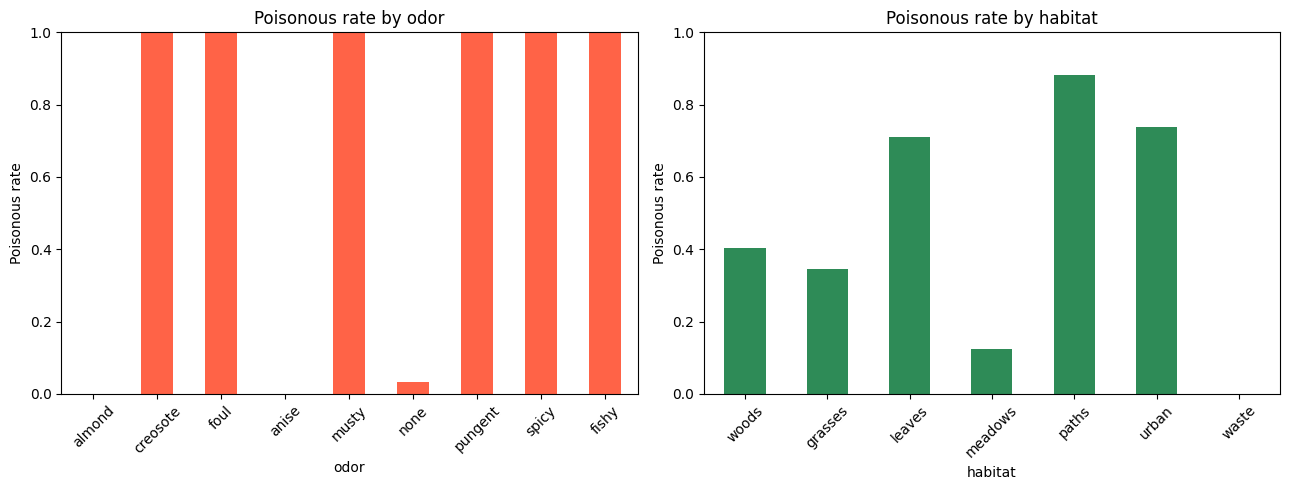

In [5]:
plot_df = df.assign(
    is_poisonous=df[TARGET].eq(POSITIVE_CLASS).astype(int)
)

odor_names = {
    "a": "almond", "c": "creosote", "f": "foul",
    "l": "anise", "m": "musty", "n": "none",
    "p": "pungent", "s": "spicy", "y": "fishy",
}
habitat_names = {
    "d": "woods", "g": "grasses", "l": "leaves",
    "m": "meadows", "p": "paths", "u": "urban", "w": "waste",
}

poison_by_odor = plot_df.groupby("odor")["is_poisonous"].mean()
poison_by_odor.index = poison_by_odor.index.map(odor_names)
poison_by_habitat = plot_df.groupby("habitat")["is_poisonous"].mean()
poison_by_habitat.index = poison_by_habitat.index.map(habitat_names)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
poison_by_odor.plot.bar(
    ax=axes[0], title="Poisonous rate by odor", color="tomato"
)
poison_by_habitat.plot.bar(
    ax=axes[1], title="Poisonous rate by habitat", color="seagreen"
)

for ax in axes:
    ax.set_ylabel("Poisonous rate")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 3. Split the data and establish a baseline

The split is stratified so the poisonous rate remains almost identical in both subsets. The training set is used for model comparison, threshold selection, and fitting. The test set stays locked until the final evaluation.

In [6]:
FEATURES = [column for column in df.columns if column != TARGET]
X, y = df[FEATURES], df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Train: {len(X_train):,} rows ({len(X_train) / len(df):.1%})")
print(f"Test:  {len(X_test):,} rows ({len(X_test) / len(df):.1%})")
print(
    "Poisonous rate: "
    f"train {y_train.eq(POSITIVE_CLASS).mean():.1%}, "
    f"test {y_test.eq(POSITIVE_CLASS).mean():.1%}"
)

Train: 6,499 rows (80.0%)
Test:  1,625 rows (20.0%)
Poisonous rate: train 48.2%, test 48.2%


### 3.1 Baseline to beat

A useful model must outperform a trivial classifier that always predicts the most common training class. Because edible mushrooms are slightly more common, this baseline always predicts `edible` and achieves roughly 51.8% accuracy while detecting no poisonous mushrooms.

In [7]:
majority_class = y_train.mode().iloc[0]
baseline_predictions = pd.Series(
    majority_class, index=y_test.index, name="prediction"
)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print(
    f"Baseline prediction: always {CLASS_NAMES[majority_class]} "
    f"({majority_class})"
)
print(f"Baseline test accuracy: {baseline_accuracy:.1%}")
print(f"Accuracy to beat: > {baseline_accuracy:.1%}")

Baseline prediction: always edible (e)
Baseline test accuracy: 51.8%
Accuracy to beat: > 51.8%


## 4. Compare five models with five-fold cross-validation

Cross-validation divides the training set into five folds, trains on four, and evaluates on the fifth. This repeats until every training row has been evaluated out of sample. The locked test set is not involved.

The candidates cover several modeling styles:

- **Logistic regression:** a regularized linear decision boundary; sparse one-hot features are scaled.
- **Decision tree:** interpretable nonlinear rules and feature interactions.
- **Random forest:** many bootstrapped trees whose votes reduce variance.
- **Extra Trees:** highly randomized trees that provide another ensemble comparison.
- **Calibrated support-vector machine:** a nonlinear boundary with calibrated probabilities.

Metrics are reported for the poisonous class (`1`). **Recall** measures how many poisonous mushrooms are caught, **precision** measures how often a poisonous prediction is correct, **F1** balances both, and **ROC AUC** measures ranking quality across thresholds.

In [8]:
y_train_binary = y_train.eq(POSITIVE_CLASS).astype(int)


def build_model_pipeline(estimator, scale=False):
    '''Create a reusable pipeline for categorical mushroom features.'''
    steps = [("encoder", OneHotEncoder(handle_unknown="ignore"))]
    if scale:
        steps.append(("scaler", StandardScaler(with_mean=False)))
    steps.append(("model", estimator))
    return Pipeline(steps)


candidates = {
    "logistic regression": build_model_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=1000), scale=True
    ),
    "decision tree": build_model_pipeline(
        DecisionTreeClassifier(
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )
    ),
    "random forest": build_model_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    ),
    "extra trees": build_model_pipeline(
        ExtraTreesClassifier(
            n_estimators=300,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    ),
    "support vector machine": build_model_pipeline(
        CalibratedClassifierCV(
            SVC(kernel="rbf", class_weight="balanced", C=1.0),
            method="sigmoid",
            cv=3,
            ensemble=False,
        ),
        scale=True,
    ),
}

folds = StratifiedKFold(
    n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE
)
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC AUC": "roc_auc",
}

rows = []
for name, candidate in candidates.items():
    cv_scores = cross_validate(
        candidate,
        X_train,
        y_train_binary,
        cv=folds,
        scoring=scoring,
        n_jobs=-1,
    )
    row = {"Model": name}
    for metric in scoring:
        values = cv_scores[f"test_{metric}"]
        row[metric] = values.mean()
        row[f"{metric} std"] = values.std()
    rows.append(row)
    print(
        f"{name:<23} ROC AUC {row['ROC AUC']:.3f} "
        f"(+/- {row['ROC AUC std']:.3f}), recall {row['Recall']:.3f}"
    )

comparison = (
    pd.DataFrame(rows)
    .set_index("Model")
    .sort_values(["ROC AUC", "Recall", "F1"], ascending=False)
)
best_name = comparison.index[0]
model = candidates[best_name]

print()
print(f"Best cross-validated model: {best_name}")
comparison.round(3)

logistic regression     ROC AUC 1.000 (+/- 0.000), recall 0.999
decision tree           ROC AUC 1.000 (+/- 0.000), recall 0.999
random forest           ROC AUC 1.000 (+/- 0.000), recall 0.999
extra trees             ROC AUC 1.000 (+/- 0.000), recall 0.999
support vector machine  ROC AUC 1.000 (+/- 0.001), recall 0.999

Best cross-validated model: decision tree


,Accuracy,Accuracy std,Precision,Precision std,Recall,Recall std,F1,F1 std,ROC AUC,ROC AUC std
Model,,,,,,,,,,
decision tree,0.999,0.001,1.0,0.0,0.999,0.003,0.999,0.001,1.0,0.000
random forest,0.999,0.001,1.0,0.0,0.999,0.003,0.999,0.001,1.0,0.000
extra trees,0.999,0.001,1.0,0.0,0.999,0.003,0.999,0.001,1.0,0.000
logistic regression,1.000,0.001,1.0,0.0,0.999,0.001,1.000,0.001,1.0,0.000
support vector machine,1.000,0.001,1.0,0.0,0.999,0.002,1.000,0.001,1.0,0.001


## 5. Choose the decision threshold

The model outputs a poisonous probability, but `0.5` is only a default classification cutoff. This project selects the threshold that maximizes F1 on **out-of-fold training probabilities**. Each training row is scored by a model that did not train on that row, and the test set remains untouched.

Threshold choice is a policy decision. In a real safety system, the cutoff might deliberately favor recall over F1 to reduce dangerous false-edible predictions.

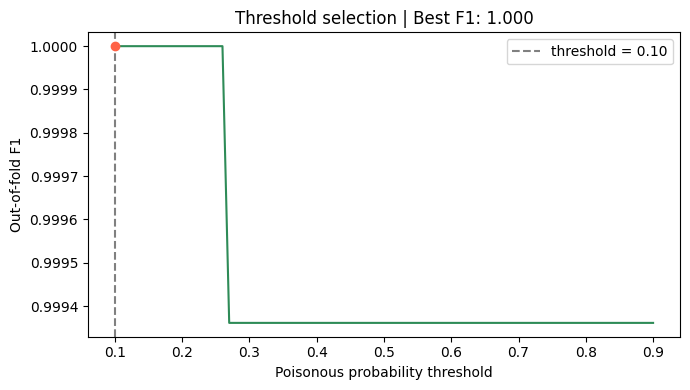

Selected threshold: 0.10
Cross-validated F1: 1.000


In [9]:
proba_cv = cross_val_predict(
    model,
    X_train,
    y_train_binary,
    cv=folds,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.01)
f1s = np.array(
    [f1_score(y_train_binary, proba_cv >= value) for value in thresholds]
)
best_index = int(np.argmax(f1s))
threshold = float(np.round(thresholds[best_index], 2))
best_cv_f1 = float(f1s[best_index])

plt.figure(figsize=(7, 4))
plt.plot(thresholds, f1s, color="seagreen")
plt.axvline(
    threshold,
    linestyle="--",
    color="grey",
    label=f"threshold = {threshold:.2f}",
)
plt.scatter(threshold, best_cv_f1, color="tomato", zorder=3)
plt.xlabel("Poisonous probability threshold")
plt.ylabel("Out-of-fold F1")
plt.title(f"Threshold selection | Best F1: {best_cv_f1:.3f}")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Selected threshold: {threshold:.2f}")
print(f"Cross-validated F1: {best_cv_f1:.3f}")

## 6. Train on all training data and evaluate once on the test set

The selected pipeline is now fitted on all training rows. The locked test set is scored once to estimate performance on unseen samples. Here, `1` means poisonous and `0` means edible.

In [10]:
y_test_binary = y_test.eq(POSITIVE_CLASS).astype(int)

model.fit(X_train, y_train_binary)
test_proba = model.predict_proba(X_test)[:, 1]
test_predicted = (test_proba >= threshold).astype(int)

test_metrics = pd.Series(
    {
        "ROC AUC": roc_auc_score(y_test_binary, test_proba),
        "Accuracy": accuracy_score(y_test_binary, test_predicted),
        "Precision (poisonous)": precision_score(
            y_test_binary, test_predicted
        ),
        "Recall (poisonous)": recall_score(y_test_binary, test_predicted),
        "F1 (poisonous)": f1_score(y_test_binary, test_predicted),
    },
    name="Test score",
)
test_metrics.round(4)

ROC AUC                  1.0000
Accuracy                 0.9994
Precision (poisonous)    0.9987
Recall (poisonous)       1.0000
F1 (poisonous)           0.9994
Name: Test score, dtype: float64

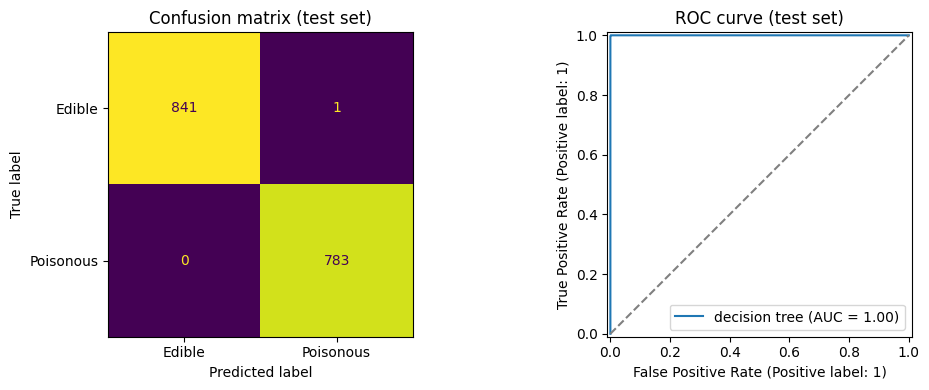

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    test_predicted,
    display_labels=["Edible", "Poisonous"],
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title("Confusion matrix (test set)")

RocCurveDisplay.from_predictions(
    y_test_binary, test_proba, ax=axes[1], name=best_name
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[1].set_title("ROC curve (test set)")
plt.tight_layout()
plt.show()

### Reading the confusion matrix

- **Bottom-right:** poisonous mushrooms correctly detected (true positives).
- **Bottom-left:** poisonous mushrooms incorrectly called edible (false negatives)—the most dangerous error.
- **Top-right:** edible mushrooms conservatively flagged as poisonous (false positives).
- **Top-left:** edible mushrooms correctly identified (true negatives).

The near-perfect result reflects how separable this particular dataset is; it should not be interpreted as proof of real-world safety.

## 7. Which mushroom features matter?

**Permutation importance** shuffles one original feature at a time and measures the decrease in ROC AUC. A larger decrease means the fitted pipeline relies more strongly on that characteristic. Importance describes this model and dataset; it is not a causal statement about mushroom toxicity.

This is post-evaluation analysis. The results should not be used to repeatedly redesign the model against the test set.

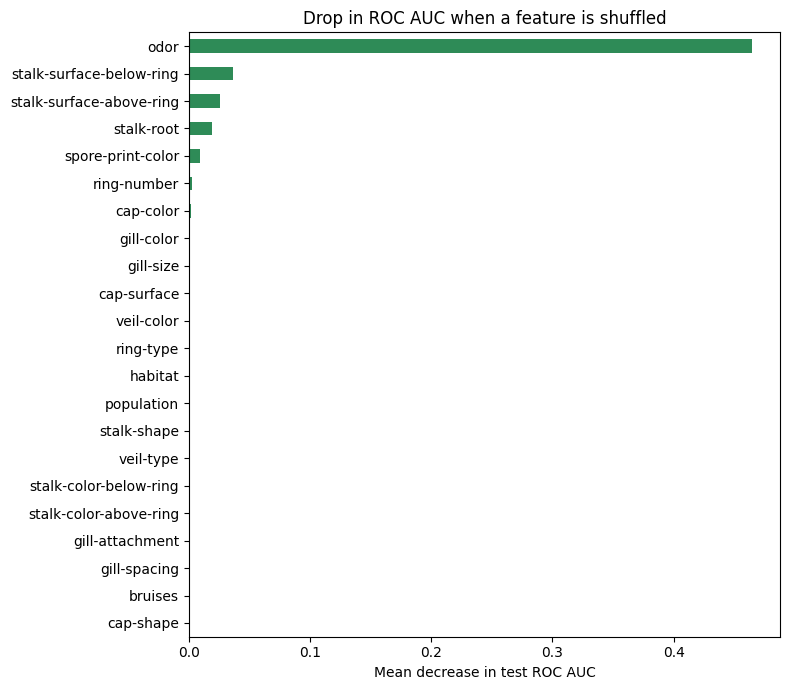

In [12]:
importance = permutation_importance(
    model,
    X_test,
    y_test_binary,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance_scores = pd.Series(
    importance.importances_mean,
    index=FEATURES,
    name="ROC AUC decrease",
).sort_values()

ax = importance_scores.plot.barh(
    figsize=(8, 7),
    color="seagreen",
    title="Drop in ROC AUC when a feature is shuffled",
)
ax.set_xlabel("Mean decrease in test ROC AUC")
plt.tight_layout()
plt.show()

## 8. Predict a new mushroom

The fitted pipeline expects the same 22 feature names used during training. Hyphenated names match the CSV and the FastAPI JSON schema. The reusable helper validates that all features are present, reorders columns, returns the poisonous probability, and applies the selected threshold.

The example then changes only `odor` to illustrate model sensitivity while holding every other characteristic fixed. This is a model-behavior experiment, not biological guidance.

> **Never consume a wild mushroom based on this prediction.**

In [13]:
def predict_mushrooms(mushrooms, fitted_model=None, cutoff=None):
    '''Return poison probabilities and threshold-based labels.'''
    fitted_model = fitted_model or model
    cutoff = threshold if cutoff is None else cutoff

    missing = set(FEATURES) - set(mushrooms.columns)
    if missing:
        raise ValueError(f"Missing features: {sorted(missing)}")

    probabilities = fitted_model.predict_proba(mushrooms[FEATURES])[:, 1]
    predictions = np.where(
        probabilities >= cutoff, "poisonous", "edible"
    )
    return pd.DataFrame(
        {
            "poisonous_probability": probabilities,
            "prediction": predictions,
        },
        index=mushrooms.index,
    )


new_mushroom = pd.DataFrame(
    [
        {
            "cap-shape": "x",
            "cap-surface": "s",
            "cap-color": "n",
            "bruises": "t",
            "odor": "p",
            "gill-attachment": "f",
            "gill-spacing": "c",
            "gill-size": "n",
            "gill-color": "k",
            "stalk-shape": "e",
            "stalk-root": "e",
            "stalk-surface-above-ring": "s",
            "stalk-surface-below-ring": "s",
            "stalk-color-above-ring": "w",
            "stalk-color-below-ring": "w",
            "veil-type": "p",
            "veil-color": "w",
            "ring-number": "o",
            "ring-type": "p",
            "spore-print-color": "k",
            "population": "s",
            "habitat": "u",
        }
    ]
)
predict_mushrooms(new_mushroom).round(4)

,poisonous_probability,prediction
0,1.0,poisonous


In [14]:
odor_scenarios = pd.concat(
    [new_mushroom.assign(odor=code) for code in odor_names],
    ignore_index=True,
)
odor_scenarios.index = [odor_names[code] for code in odor_names]
odor_scenarios.index.name = "odor"

predict_mushrooms(odor_scenarios).sort_values(
    "poisonous_probability", ascending=False
).round(4)

,poisonous_probability,prediction
odor,,
creosote,1.0,poisonous
fishy,1.0,poisonous
foul,1.0,poisonous
musty,1.0,poisonous
pungent,1.0,poisonous
spicy,1.0,poisonous
almond,0.0,edible
anise,0.0,edible
none,0.0,edible


## 9. Save the model for the API

The API needs more than the estimator. The saved bundle includes the fitted preprocessing-and-classification pipeline, algorithm name, exact feature order, target and class labels, decision threshold, test metrics, UTC training timestamp, and scikit-learn version.

`joblib` files can execute code while loading, so the API must load only trusted artifacts produced by this project.

In [15]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

bundle = {
    "model": model,
    "algorithm": best_name,
    "features": FEATURES,
    "target": TARGET,
    "class_labels": BINARY_CLASS_LABELS,
    "threshold": threshold,
    "metrics": {
        str(name): round(float(value), 4)
        for name, value in test_metrics.items()
    },
    "trained_at": pd.Timestamp.now(tz="UTC").isoformat(
        timespec="seconds"
    ),
    "sklearn_version": sklearn.__version__,
}

joblib.dump(bundle, MODEL_PATH)
print(f"Saved model bundle to: {MODEL_PATH}")

Saved model bundle to: C:\Users\USER\Documents\Techpreneur Bootcamp\Data Science\Mushroom Classificaion\models\mushroom.joblib


## 10. Results, limitations, and next steps

### Results

With the fixed random seed and current dataset, the workflow selects a **decision tree** and an F1-optimized threshold near **0.10**. Its locked-test performance is approximately **99.94% accuracy**, **99.87% poisonous precision**, **100% poisonous recall**, **99.94% F1**, and **1.00 ROC AUC**. Exact displayed values are generated by the cells above and saved with the model.

The completed project produces:

- a fitted categorical preprocessing and classification pipeline;
- an explicit, training-derived probability threshold;
- final test metrics and diagnostic plots;
- original-feature permutation importance;
- reusable single-row and batch prediction logic;
- a versioned `models/mushroom.joblib` bundle consumed by `app/main.py`.

### Limitations

- The data contains compact category codes rather than measurements or images.
- `stalk-root` has 2,480 unknown (`?`) values, treated as their own category.
- `veil-type` is constant and contributes no predictive information.
- Near-perfect performance may reflect strong dataset-specific patterns that do not transfer to new regions, species, collection practices, or real-world observations.
- Permutation importance explains reliance, not causality.
- Probability calibration and threshold behavior should be rechecked after any data or model change.
- This classifier is not a substitute for an expert mycologist or public-health guidance.

### Recommended next steps

1. Add external validation data collected independently from the training source.
2. Monitor category drift, prediction confidence, and false-negative rates.
3. Version the dataset, schema, model bundle, and API together.
4. Retrain with `python mushroom_train.py` whenever the data or dependencies change.
5. Run `python -m pytest -q` before deploying the FastAPI service.